# Gemini vs Qwen - RCA Evaluation Comparison

This notebook loads the extracted model I/O JSON and compares Gemini and Qwen across where, why, full RCA, fault types, services, and strategies S0-S5.

In [ ]:
from __future__ import annotations

import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

try:
    import seaborn as sns
except ImportError:
    sns = None

plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', 120)
pd.set_option('display.max_colwidth', 140)

ROOT = Path.cwd()
JSON_PATH = ROOT / 'out/model_io_last_gemini_qwen.json'
assert JSON_PATH.exists(), f'Missing input JSON: {JSON_PATH}'
JSON_PATH

PosixPath('/home/daniel/projetos/microservices-demo/experiment/eval/memory_hog/out/model_io_last_gemini_qwen.json')

In [3]:
def norm(value):
    return str(value or '').strip().lower().replace('_', '-').replace(' ', '-')


def short_strategy(strategy):
    match = re.match(r'(S\d+)', str(strategy or ''))
    return match.group(1) if match else str(strategy or '')


def friendly_status(row):
    if row.get('error'):
        return 'error'
    if row.get('parse_error'):
        return 'parse_error'
    if row.get('final_status') == 'ok':
        return 'ok'
    return str(row.get('final_status') or 'unknown')


data = json.loads(JSON_PATH.read_text(encoding='utf-8'))
records = []

for provider, provider_payload in data['providers'].items():
    for cell in provider_payload.get('cells_summary', []):
        expected_service = cell.get('eval_target')
        expected_fault = cell.get('eval_fault')
        pred_service = cell.get('parsed_rca')
        pred_fault = cell.get('parsed_fault_category')
        http_ok = cell.get('final_status') == 'ok' and not cell.get('error')
        parse_ok = http_ok and not cell.get('parse_error') and bool(pred_service or pred_fault)
        where_ok = parse_ok and pred_service == expected_service
        why_ok = parse_ok and norm(pred_fault) == norm(expected_fault)
        records.append({
            'provider': provider,
            'model': cell.get('model'),
            'run_id': cell.get('run_id'),
            'strategy': cell.get('eval_strategy'),
            'strategy_short': short_strategy(cell.get('eval_strategy')),
            'expected_service': expected_service,
            'expected_fault': expected_fault,
            'pred_service': pred_service or 'missing',
            'pred_fault': norm(pred_fault) or 'missing',
            'confidence': cell.get('parsed_confidence'),
            'status': friendly_status(cell),
            'http_ok': http_ok,
            'parse_ok': parse_ok,
            'where_ok': where_ok,
            'why_ok': why_ok,
            'full_ok': where_ok and why_ok,
            'attempt_count': cell.get('attempt_count') or 0,
            'prompt_tokens': cell.get('prompt_tokens_estimate'),
            'response_chars': cell.get('response_chars'),
            'prompt_sha256': cell.get('prompt_sha256'),
            'parse_error': cell.get('parse_error'),
            'error': cell.get('error'),
        })

df = pd.DataFrame(records)
strategy_order = sorted(df['strategy_short'].dropna().unique(), key=lambda s: int(s[1:]) if s.startswith('S') and s[1:].isdigit() else 99)
provider_order = ['qwen', 'gemini']
df.head()

,provider,model,run_id,strategy,strategy_short,expected_service,expected_fault,pred_service,pred_fault,confidence,status,http_ok,parse_ok,where_ok,why_ok,full_ok,attempt_count,prompt_tokens,response_chars,prompt_sha256,parse_error,error
0,gemini,gemini-2.5-flash,run-0780a28e7575,S0_no_rag,S0,queue-master,cpu-exhaustion,queue-master,cpu-exhaustion,0.8,ok,True,True,True,True,True,1,2486.0,630,23d4b037f11377929e0df9be324e0487e8515425621d54faa355fcc4551e4005,None,None
1,gemini,gemini-2.5-flash,run-0780a28e7575,S1_rag_tags,S1,queue-master,cpu-exhaustion,missing,missing,NaN,error,False,False,False,False,False,1,NaN,0,14a381ec15e2fe074e8ea54341570531510a07fd5997c91252ad0956839aa6ae,None,Gemini APIError 504: The request timed out. Please try again.
2,gemini,gemini-2.5-flash,run-0780a28e7575,S2_rag_embeddings,S2,queue-master,cpu-exhaustion,missing,missing,NaN,error,False,False,False,False,False,1,NaN,0,4470c21dfccda7fa82fd99400a41033b2a5e55768c6110abf28e44cfe9f69e56,None,Gemini APIError 503: This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.
3,gemini,gemini-2.5-flash,run-0780a28e7575,S3_rag_hybrid,S3,queue-master,cpu-exhaustion,missing,missing,NaN,error,False,False,False,False,False,1,NaN,0,86f84673b497dc1be3019532be55495b4f52ac241f0bfe883527935057a7d723,None,Gemini APIError 503: This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.
4,gemini,gemini-2.5-flash,run-0780a28e7575,S4_rag_embeddings_no_card,S4,queue-master,cpu-exhaustion,queue-master,resource-exhaustion,0.9,ok,True,True,True,False,False,1,3648.0,647,20ee0cab63e988a7070a7f59946c8ca3e083ef6940ae9cd2d2e7493d552bb025,None,None


In [4]:
overview = (
    df.groupby('provider')
    .agg(
        cells=('run_id', 'count'),
        http_ok=('http_ok', 'sum'),
        parse_ok=('parse_ok', 'sum'),
        where_ok=('where_ok', 'sum'),
        why_ok=('why_ok', 'sum'),
        full_ok=('full_ok', 'sum'),
        avg_attempts=('attempt_count', 'mean'),
        avg_prompt_tokens=('prompt_tokens', 'mean'),
        avg_response_chars=('response_chars', 'mean'),
    )
    .reset_index()
)
for col in ['http_ok', 'parse_ok', 'where_ok', 'why_ok', 'full_ok']:
    overview[col + '_rate'] = overview[col] / overview['cells']
overview

,provider,cells,http_ok,parse_ok,where_ok,why_ok,full_ok,avg_attempts,avg_prompt_tokens,avg_response_chars,http_ok_rate,parse_ok_rate,where_ok_rate,why_ok_rate,full_ok_rate
0,gemini,60,56,56,26,26,17,1.000000,3877.821429,632.55,0.933333,0.933333,0.433333,0.433333,0.283333
1,qwen,60,60,55,26,11,10,1.216667,4008.000000,968.25,1.000000,0.916667,0.433333,0.183333,0.166667


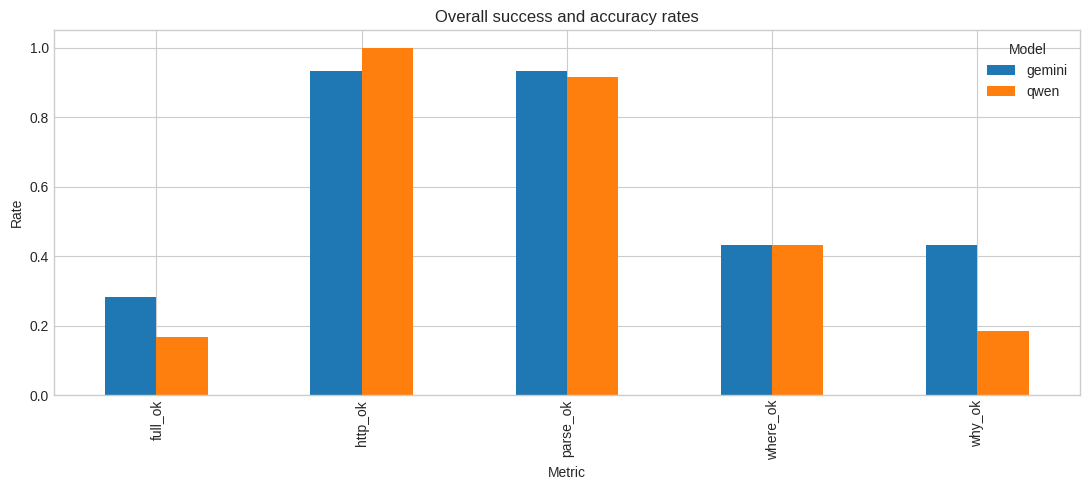

In [5]:
metrics_long = overview.melt(
    id_vars='provider',
    value_vars=['http_ok_rate', 'parse_ok_rate', 'where_ok_rate', 'why_ok_rate', 'full_ok_rate'],
    var_name='metric',
    value_name='rate',
)
metrics_long['metric'] = metrics_long['metric'].str.replace('_rate', '', regex=False)

fig, ax = plt.subplots(figsize=(11, 5))
if sns:
    sns.barplot(data=metrics_long, x='metric', y='rate', hue='provider', hue_order=provider_order, ax=ax)
else:
    metrics_long.pivot(index='metric', columns='provider', values='rate').plot(kind='bar', ax=ax)
ax.set_title('Overall success and accuracy rates')
ax.set_xlabel('Metric')
ax.set_ylabel('Rate')
ax.set_ylim(0, 1.05)
ax.legend(title='Model')
plt.tight_layout()

## Strategy View

Compare S0-S5 across where, why, and full RCA.

In [6]:
strategy_summary = (
    df.groupby(['provider', 'strategy_short'])
    .agg(
        cells=('run_id', 'count'),
        where_rate=('where_ok', 'mean'),
        why_rate=('why_ok', 'mean'),
        full_rate=('full_ok', 'mean'),
        parse_rate=('parse_ok', 'mean'),
        avg_attempts=('attempt_count', 'mean'),
        avg_tokens=('prompt_tokens', 'mean'),
    )
    .reset_index()
)
strategy_summary['strategy_short'] = pd.Categorical(strategy_summary['strategy_short'], strategy_order, ordered=True)
strategy_summary = strategy_summary.sort_values(['provider', 'strategy_short'])
strategy_summary

,provider,strategy_short,cells,where_rate,why_rate,full_rate,parse_rate,avg_attempts,avg_tokens
0,gemini,S0,10,0.6,0.6,0.5,1.0,1.0,2768.900000
1,gemini,S1,10,0.4,0.6,0.4,0.9,1.0,4647.666667
2,gemini,S2,10,0.4,0.5,0.4,0.9,1.0,4649.111111
3,gemini,S3,10,0.6,0.4,0.3,0.9,1.0,4649.111111
4,gemini,S4,10,0.5,0.1,0.0,1.0,1.0,3651.600000
5,gemini,S5,10,0.1,0.4,0.1,0.9,1.0,3048.888889
6,qwen,S0,10,0.2,0.2,0.2,0.5,1.8,2798.200000
7,qwen,S1,10,0.6,0.3,0.3,1.0,1.1,4647.300000
8,qwen,S2,10,0.7,0.2,0.2,1.0,1.1,4648.700000
9,qwen,S3,10,0.6,0.2,0.2,1.0,1.1,4648.700000


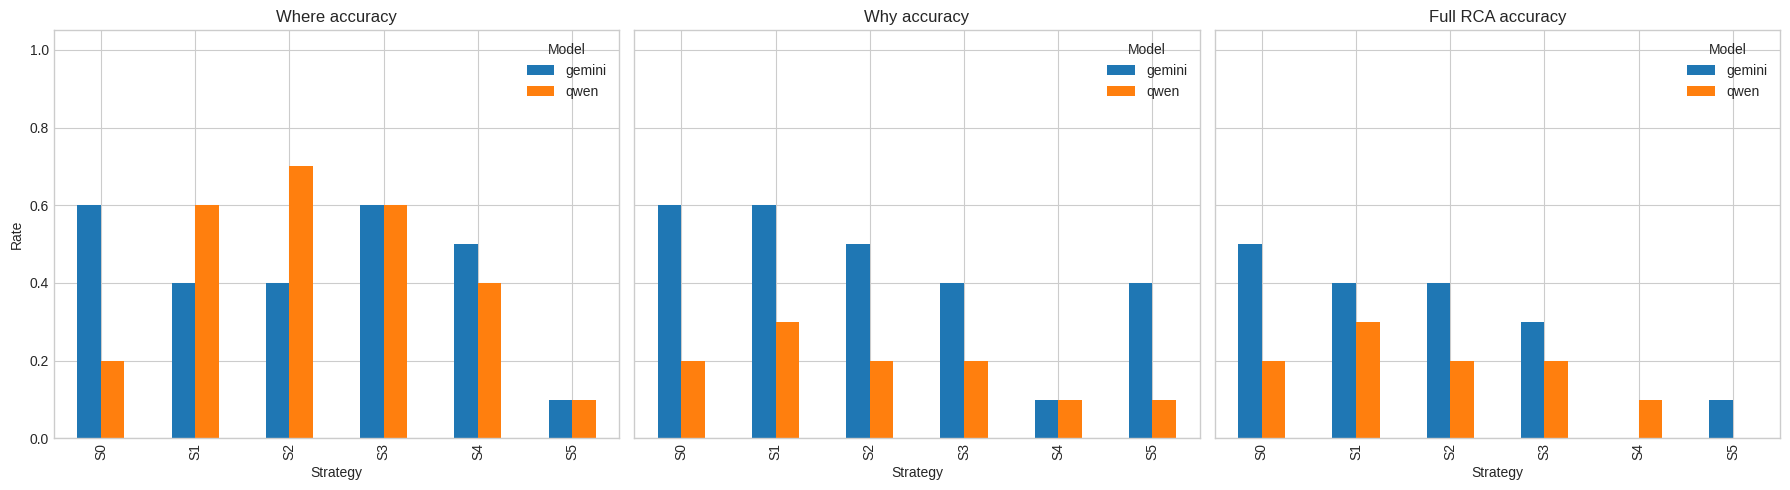

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for ax, metric, title in zip(axes, ['where_rate', 'why_rate', 'full_rate'], ['Where accuracy', 'Why accuracy', 'Full RCA accuracy']):
    if sns:
        sns.barplot(data=strategy_summary, x='strategy_short', y=metric, hue='provider', hue_order=provider_order, ax=ax)
    else:
        strategy_summary.pivot(index='strategy_short', columns='provider', values=metric).plot(kind='bar', ax=ax)
    ax.set_title(title)
    ax.set_xlabel('Strategy')
    ax.set_ylabel('Rate')
    ax.set_ylim(0, 1.05)
    ax.legend(title='Model')
plt.tight_layout()

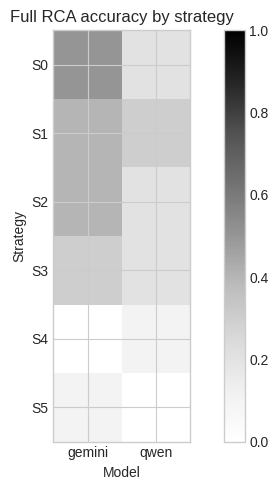

In [8]:
heatmap_data = strategy_summary.pivot(index='strategy_short', columns='provider', values='full_rate').reindex(strategy_order)
fig, ax = plt.subplots(figsize=(7, 5))
if sns:
    sns.heatmap(heatmap_data, annot=True, fmt='.0%', cmap='YlGnBu', vmin=0, vmax=1, ax=ax)
else:
    im = ax.imshow(heatmap_data.fillna(0), vmin=0, vmax=1)
    ax.set_xticks(range(len(heatmap_data.columns)), heatmap_data.columns)
    ax.set_yticks(range(len(heatmap_data.index)), heatmap_data.index)
    fig.colorbar(im, ax=ax)
ax.set_title('Full RCA accuracy by strategy')
ax.set_xlabel('Model')
ax.set_ylabel('Strategy')
plt.tight_layout()

## Fault Type View

Break down where and why by injected fault category.

In [9]:
fault_summary = (
    df.groupby(['provider', 'expected_fault'])
    .agg(
        cells=('run_id', 'count'),
        where_rate=('where_ok', 'mean'),
        why_rate=('why_ok', 'mean'),
        full_rate=('full_ok', 'mean'),
        parse_rate=('parse_ok', 'mean'),
    )
    .reset_index()
)
fault_summary

,provider,expected_fault,cells,where_rate,why_rate,full_rate,parse_rate
0,gemini,cpu-exhaustion,12,0.500000,0.250000,0.250000,0.666667
1,gemini,http-error,6,0.000000,0.000000,0.000000,1.000000
2,gemini,memory-exhaustion,12,0.833333,0.666667,0.666667,1.000000
3,gemini,network-latency,6,0.166667,0.166667,0.000000,1.000000
4,gemini,network-loss,6,0.000000,1.000000,0.000000,1.000000
5,gemini,pod-failure,18,0.500000,0.444444,0.333333,1.000000
6,qwen,cpu-exhaustion,12,0.500000,0.083333,0.083333,0.833333
7,qwen,http-error,6,0.000000,0.000000,0.000000,0.833333
8,qwen,memory-exhaustion,12,0.833333,0.750000,0.750000,1.000000
9,qwen,network-latency,6,0.000000,0.000000,0.000000,1.000000


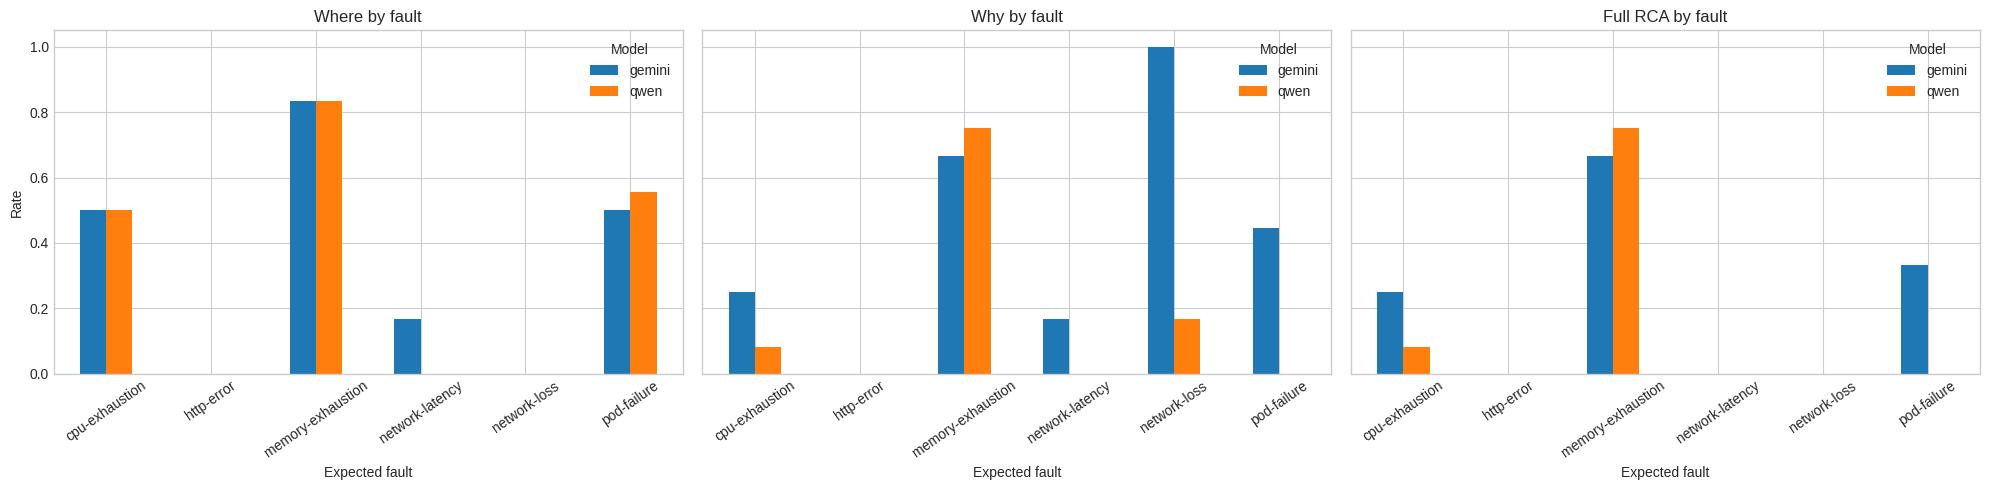

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5), sharey=True)
for ax, metric, title in zip(axes, ['where_rate', 'why_rate', 'full_rate'], ['Where by fault', 'Why by fault', 'Full RCA by fault']):
    if sns:
        sns.barplot(data=fault_summary, x='expected_fault', y=metric, hue='provider', hue_order=provider_order, ax=ax)
    else:
        fault_summary.pivot(index='expected_fault', columns='provider', values=metric).plot(kind='bar', ax=ax)
    ax.set_title(title)
    ax.set_xlabel('Expected fault')
    ax.set_ylabel('Rate')
    ax.tick_params(axis='x', rotation=35)
    ax.set_ylim(0, 1.05)
    ax.legend(title='Model')
plt.tight_layout()

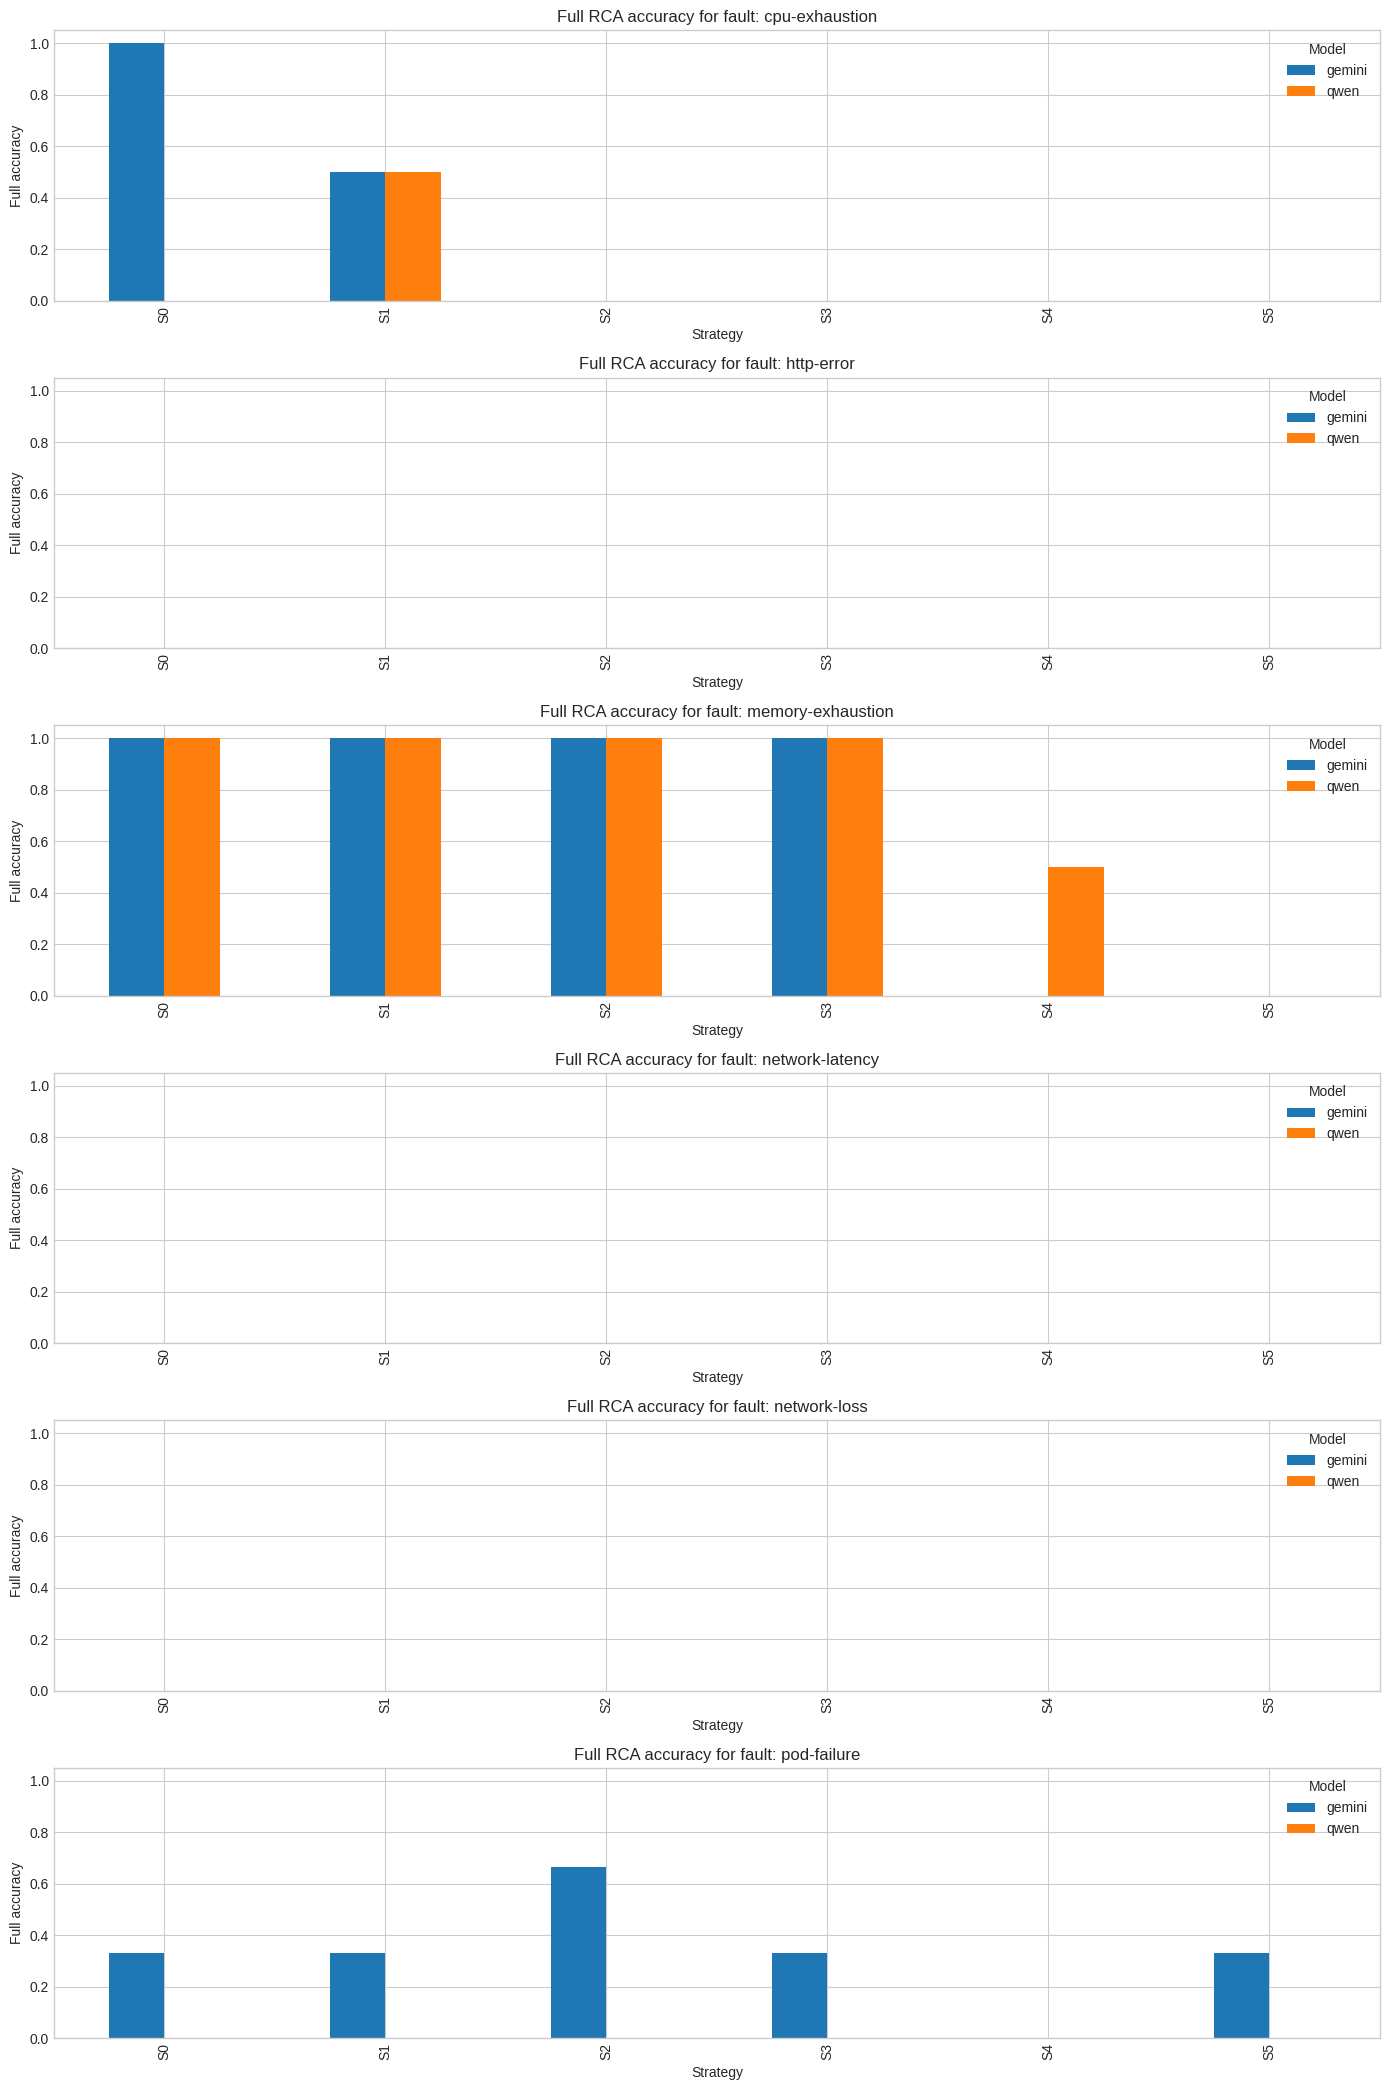

In [11]:
fault_strategy = (
    df.groupby(['provider', 'expected_fault', 'strategy_short'])['full_ok']
    .mean()
    .reset_index()
)
faults = sorted(df['expected_fault'].dropna().unique())
fig, axes = plt.subplots(len(faults), 1, figsize=(14, max(4, 3.5 * len(faults))), sharey=True)
if len(faults) == 1:
    axes = [axes]
for ax, fault in zip(axes, faults):
    subset = fault_strategy[fault_strategy['expected_fault'] == fault].copy()
    subset['strategy_short'] = pd.Categorical(subset['strategy_short'], strategy_order, ordered=True)
    if sns:
        sns.barplot(data=subset, x='strategy_short', y='full_ok', hue='provider', hue_order=provider_order, ax=ax)
    else:
        subset.pivot(index='strategy_short', columns='provider', values='full_ok').plot(kind='bar', ax=ax)
    ax.set_title(f'Full RCA accuracy for fault: {fault}')
    ax.set_xlabel('Strategy')
    ax.set_ylabel('Full accuracy')
    ax.set_ylim(0, 1.05)
    ax.legend(title='Model')
plt.tight_layout()

## Service View

Compare localization performance by injected service.

In [12]:
service_summary = (
    df.groupby(['provider', 'expected_service'])
    .agg(
        cells=('run_id', 'count'),
        where_rate=('where_ok', 'mean'),
        why_rate=('why_ok', 'mean'),
        full_rate=('full_ok', 'mean'),
    )
    .reset_index()
)
service_summary

,provider,expected_service,cells,where_rate,why_rate,full_rate
0,gemini,front-end,6,0.500000,0.333333,0.333333
1,gemini,orders,12,0.416667,0.333333,0.333333
2,gemini,payment,6,0.166667,0.166667,0.000000
3,gemini,queue-master,6,0.333333,0.166667,0.166667
4,gemini,shipping,12,0.083333,0.666667,0.000000
5,gemini,user,18,0.777778,0.555556,0.555556
6,qwen,front-end,6,0.833333,0.000000,0.000000
7,qwen,orders,12,0.416667,0.333333,0.333333
8,qwen,payment,6,0.000000,0.000000,0.000000
9,qwen,queue-master,6,0.666667,0.000000,0.000000


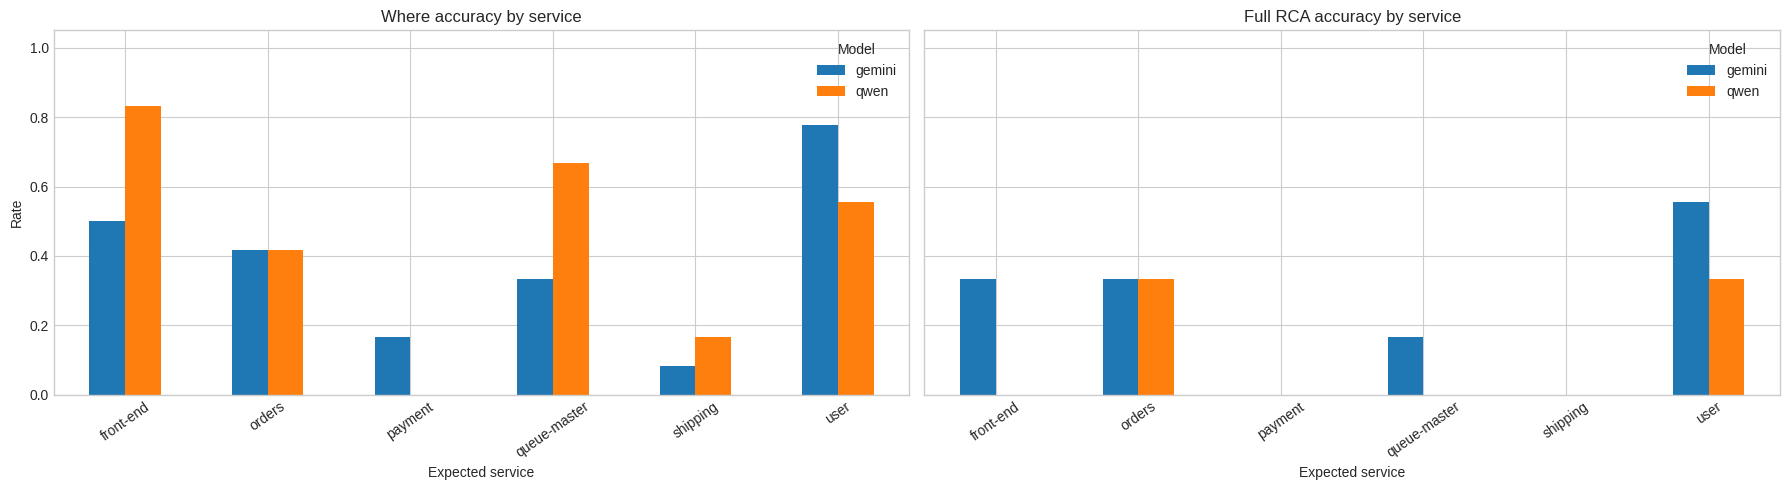

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5), sharey=True)
for ax, metric, title in zip(axes, ['where_rate', 'full_rate'], ['Where accuracy by service', 'Full RCA accuracy by service']):
    if sns:
        sns.barplot(data=service_summary, x='expected_service', y=metric, hue='provider', hue_order=provider_order, ax=ax)
    else:
        service_summary.pivot(index='expected_service', columns='provider', values=metric).plot(kind='bar', ax=ax)
    ax.set_title(title)
    ax.set_xlabel('Expected service')
    ax.set_ylabel('Rate')
    ax.tick_params(axis='x', rotation=35)
    ax.set_ylim(0, 1.05)
    ax.legend(title='Model')
plt.tight_layout()

## Confusion Matrices

These charts show which services and fault categories each model tends to predict.

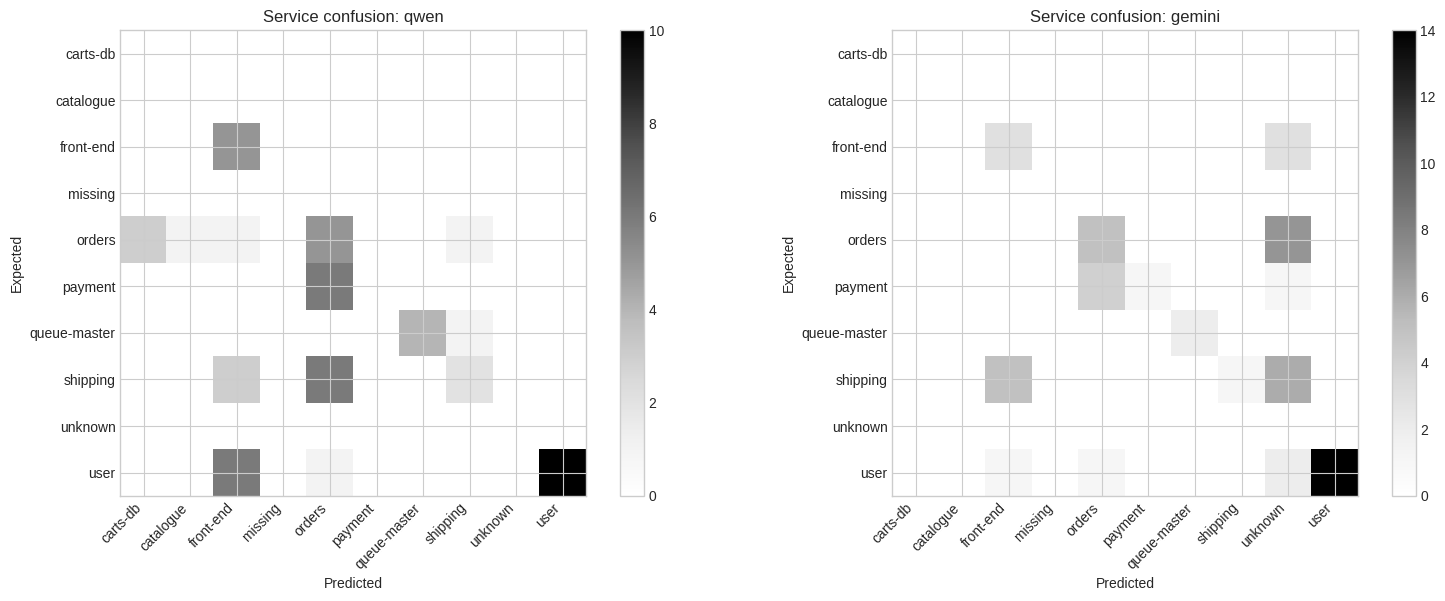

In [14]:
def plot_confusion(dataframe, expected_col, predicted_col, title_prefix):
    providers = [p for p in provider_order if p in set(dataframe['provider'])]
    fig, axes = plt.subplots(1, len(providers), figsize=(8 * len(providers), 6))
    if len(providers) == 1:
        axes = [axes]
    labels = sorted(set(dataframe[expected_col].dropna()) | set(dataframe[predicted_col].dropna()))
    for ax, provider in zip(axes, providers):
        subset = dataframe[(dataframe['provider'] == provider) & (dataframe['parse_ok'])]
        cm = pd.crosstab(subset[expected_col], subset[predicted_col]).reindex(index=labels, columns=labels, fill_value=0)
        if sns:
            sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax)
        else:
            im = ax.imshow(cm.values)
            ax.set_xticks(range(len(cm.columns)), cm.columns, rotation=45, ha='right')
            ax.set_yticks(range(len(cm.index)), cm.index)
            fig.colorbar(im, ax=ax)
        ax.set_title(f'{title_prefix}: {provider}')
        ax.set_xlabel('Predicted')
        ax.set_ylabel('Expected')
    plt.tight_layout()


plot_confusion(df, 'expected_service', 'pred_service', 'Service confusion')

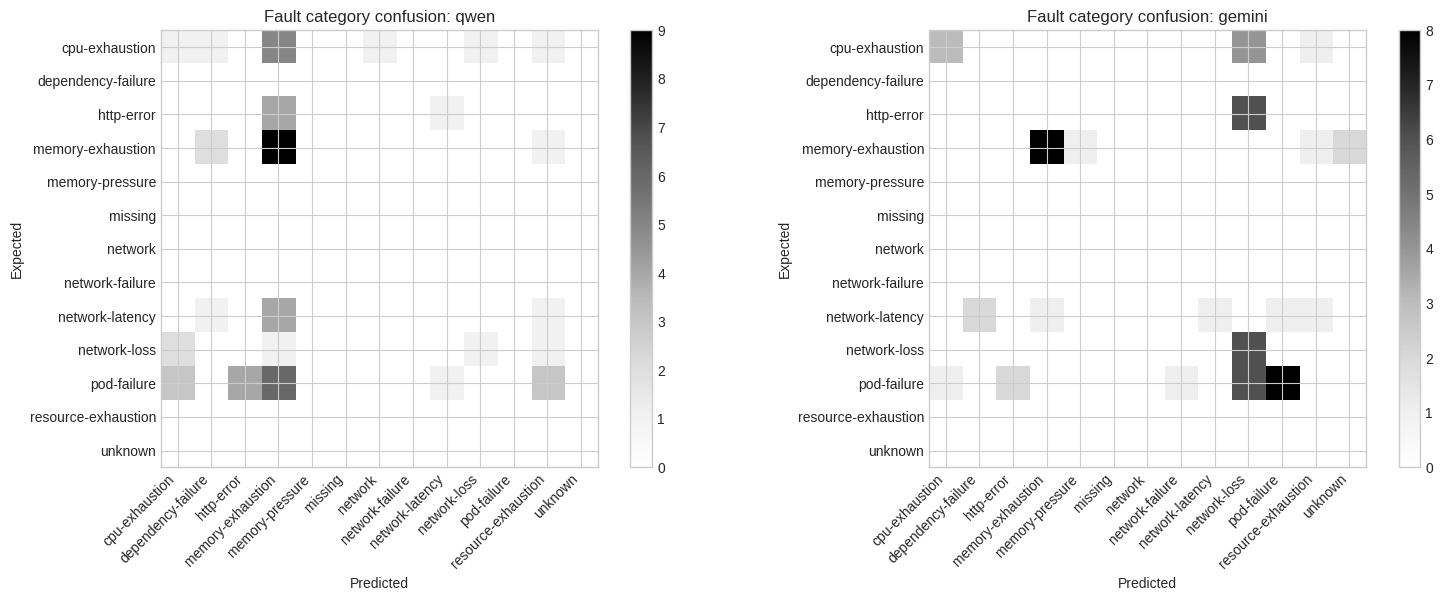

In [15]:
plot_confusion(df, 'expected_fault', 'pred_fault', 'Fault category confusion')

## Prompt Fairness

For the same run and strategy, prompt hashes should match between Gemini and Qwen.

In [16]:
prompt_compare = df.pivot_table(
    index=['run_id', 'strategy_short', 'expected_service', 'expected_fault'],
    columns='provider',
    values=['prompt_sha256', 'prompt_tokens'],
    aggfunc='first',
)
prompt_compare.columns = [f'{field}_{provider}' for field, provider in prompt_compare.columns]
prompt_compare = prompt_compare.reset_index()
prompt_compare['same_prompt_hash'] = prompt_compare.get('prompt_sha256_gemini') == prompt_compare.get('prompt_sha256_qwen')
prompt_compare['same_token_estimate'] = prompt_compare.get('prompt_tokens_gemini') == prompt_compare.get('prompt_tokens_qwen')
prompt_compare[['same_prompt_hash', 'same_token_estimate']].mean()

same_prompt_hash       1.00
same_token_estimate    0.85
dtype: float64

In [17]:
mismatch = prompt_compare[~prompt_compare['same_prompt_hash'].fillna(False)]
mismatch[['run_id', 'strategy_short', 'expected_service', 'expected_fault', 'prompt_sha256_gemini', 'prompt_sha256_qwen', 'prompt_tokens_gemini', 'prompt_tokens_qwen']].head(30)

,run_id,strategy_short,expected_service,expected_fault,prompt_sha256_gemini,prompt_sha256_qwen,prompt_tokens_gemini,prompt_tokens_qwen


## Reliability, Retries, and Output Size

These views help separate model quality from endpoint availability and retry behavior.

,provider,status,count
0,gemini,error,4
1,gemini,ok,56
2,qwen,ok,55
3,qwen,parse_error,5


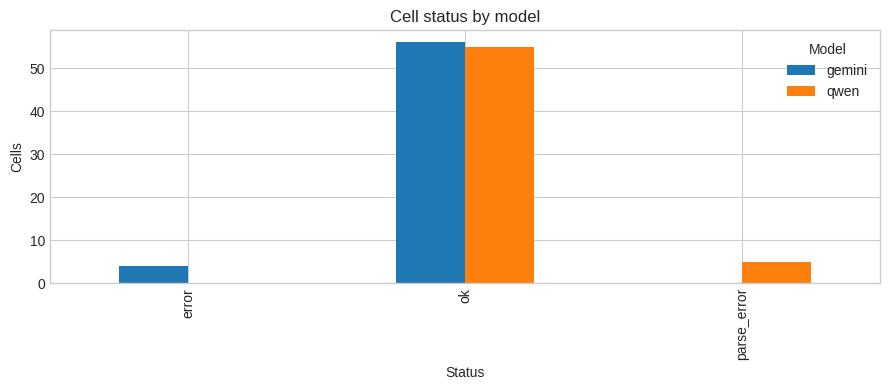

In [18]:
status_counts = df.groupby(['provider', 'status']).size().reset_index(name='count')
fig, ax = plt.subplots(figsize=(9, 4))
if sns:
    sns.barplot(data=status_counts, x='status', y='count', hue='provider', hue_order=provider_order, ax=ax)
else:
    status_counts.pivot(index='status', columns='provider', values='count').fillna(0).plot(kind='bar', ax=ax)
ax.set_title('Cell status by model')
ax.set_xlabel('Status')
ax.set_ylabel('Cells')
ax.legend(title='Model')
plt.tight_layout()
status_counts

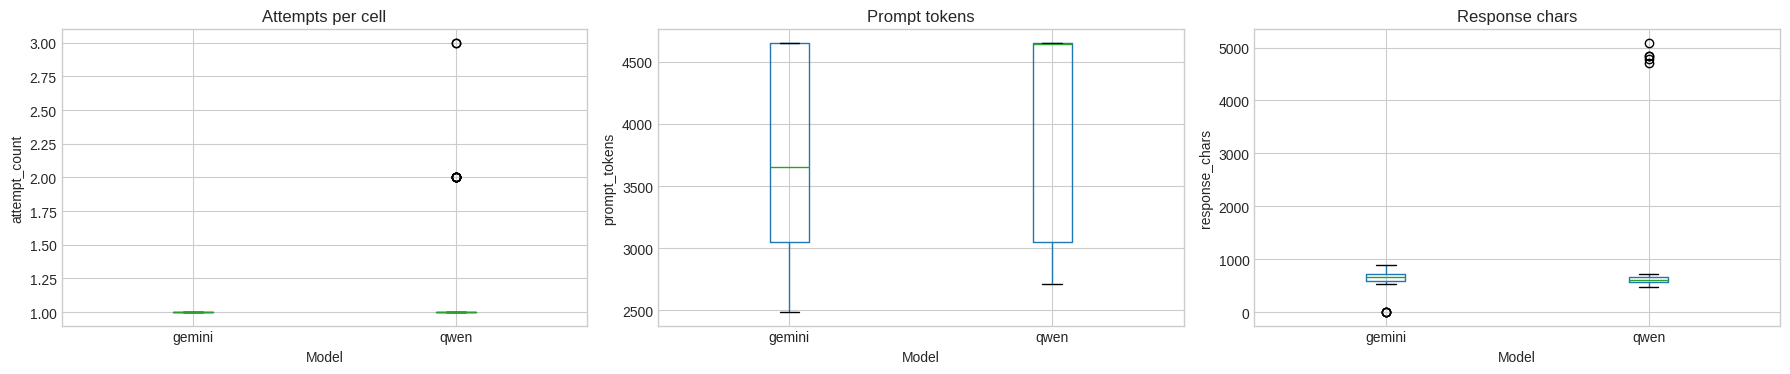

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, column, title in zip(axes, ['attempt_count', 'prompt_tokens', 'response_chars'], ['Attempts per cell', 'Prompt tokens', 'Response chars']):
    plot_df = df.dropna(subset=[column])
    if sns:
        sns.boxplot(data=plot_df, x='provider', y=column, order=provider_order, ax=ax)
        sns.stripplot(data=plot_df, x='provider', y=column, order=provider_order, color='black', alpha=0.35, ax=ax)
    else:
        plot_df.boxplot(column=column, by='provider', ax=ax)
    ax.set_title(title)
    ax.set_xlabel('Model')
    ax.set_ylabel(column)
plt.suptitle('')
plt.tight_layout()

## Disagreements

Inspect cells where the models made different predictions for the same run and strategy.

In [20]:
wide = df.pivot_table(
    index=['run_id', 'strategy_short', 'expected_service', 'expected_fault'],
    columns='provider',
    values=['pred_service', 'pred_fault', 'where_ok', 'why_ok', 'full_ok', 'status'],
    aggfunc='first',
)
wide.columns = [f'{field}_{provider}' for field, provider in wide.columns]
wide = wide.reset_index()
wide['service_disagree'] = wide.get('pred_service_gemini') != wide.get('pred_service_qwen')
wide['fault_disagree'] = wide.get('pred_fault_gemini') != wide.get('pred_fault_qwen')
disagreements = wide[wide['service_disagree'].fillna(False) | wide['fault_disagree'].fillna(False)]
disagreements.sort_values(['strategy_short', 'expected_fault', 'expected_service']).head(60)

,run_id,strategy_short,expected_service,expected_fault,full_ok_gemini,full_ok_qwen,pred_fault_gemini,pred_fault_qwen,pred_service_gemini,pred_service_qwen,status_gemini,status_qwen,where_ok_gemini,where_ok_qwen,why_ok_gemini,why_ok_qwen,service_disagree,fault_disagree
0,run-0780a28e7575,S0,queue-master,cpu-exhaustion,True,False,cpu-exhaustion,missing,queue-master,missing,ok,parse_error,True,False,True,False,True,True
30,run-4565a5d911fe,S0,user,cpu-exhaustion,True,False,cpu-exhaustion,missing,user,missing,ok,parse_error,True,False,True,False,True,True
6,run-126a7ca8141f,S0,orders,http-error,False,False,network-loss,missing,unknown,missing,ok,parse_error,False,False,False,False,True,True
36,run-510ade01a44a,S0,payment,network-latency,False,False,dependency-failure,memory-exhaustion,orders,orders,ok,ok,False,False,False,False,False,True
54,run-f141ce8363d3,S0,shipping,network-loss,False,False,network-loss,missing,unknown,missing,ok,parse_error,False,False,True,False,True,True
48,run-e9513aa3fb7c,S0,front-end,pod-failure,False,False,network-loss,missing,unknown,missing,ok,parse_error,False,False,False,False,True,True
24,run-41abe3b46051,S0,shipping,pod-failure,False,False,cpu-exhaustion,http-error,shipping,front-end,ok,ok,True,False,False,False,True,True
42,run-72819caed47f,S0,user,pod-failure,True,False,pod-failure,http-error,user,front-end,ok,ok,True,False,True,False,True,True
1,run-0780a28e7575,S1,queue-master,cpu-exhaustion,False,False,missing,memory-exhaustion,missing,queue-master,error,ok,False,True,False,False,True,True
7,run-126a7ca8141f,S1,orders,http-error,False,False,network-loss,memory-exhaustion,unknown,carts-db,ok,ok,False,False,False,False,True,True


In [21]:
attempt_records = []
for provider, provider_payload in data['providers'].items():
    for attempt in provider_payload.get('attempts', []):
        parsed = (attempt.get('output') or {}).get('parsed') or {}
        attempt_records.append({
            'provider': provider,
            'run_id': attempt.get('run_id'),
            'strategy': attempt.get('eval_strategy'),
            'strategy_short': short_strategy(attempt.get('eval_strategy')),
            'attempt': attempt.get('attempt'),
            'retry': bool(attempt.get('retry')),
            'status': attempt.get('status'),
            'expected_service': attempt.get('eval_target'),
            'expected_fault': attempt.get('eval_fault'),
            'parsed_rca': parsed.get('rca'),
            'parsed_fault': norm(parsed.get('fault_category')),
            'confidence': parsed.get('confidence'),
            'prompt_tokens': attempt.get('prompt_tokens_estimate'),
            'response_chars': (attempt.get('output') or {}).get('response_chars'),
            'error': attempt.get('error'),
            'raw_response': (attempt.get('output') or {}).get('raw_response'),
        })
attempts_df = pd.DataFrame(attempt_records)
attempts_df[['provider', 'run_id', 'strategy_short', 'attempt', 'retry', 'status', 'parsed_rca', 'parsed_fault', 'confidence', 'error']].head(80)

,provider,run_id,strategy_short,attempt,retry,status,parsed_rca,parsed_fault,confidence,error
0,gemini,run-1f9afa1913a3,S0,1,False,ok,user,memory-exhaustion,0.90,None
1,gemini,run-1f9afa1913a3,S1,1,False,ok,user,memory-exhaustion,0.90,None
2,gemini,run-1f9afa1913a3,S2,1,False,ok,user,memory-exhaustion,0.90,None
3,gemini,run-1f9afa1913a3,S3,1,False,ok,user,memory-exhaustion,0.90,None
4,gemini,run-1f9afa1913a3,S4,1,False,ok,user,memory-pressure,0.90,None
...,...,...,...,...,...,...,...,...,...,...
75,qwen,run-4565a5d911fe,S0,2,True,ok,None,,NaN,None
76,qwen,run-4565a5d911fe,S1,1,False,ok,user,cpu-exhaustion,0.90,None
77,qwen,run-4565a5d911fe,S2,1,False,ok,user,memory-exhaustion,0.85,None
78,qwen,run-4565a5d911fe,S3,1,False,ok,front-end,dependency-failure,0.85,None


In [22]:
error_rows = attempts_df[attempts_df['error'].notna() & (attempts_df['error'] != '')].copy()
error_rows[['provider', 'run_id', 'strategy_short', 'attempt', 'expected_service', 'expected_fault', 'error']].head(50)

,provider,run_id,strategy_short,attempt,expected_service,expected_fault,error
19,gemini,run-0780a28e7575,S1,1,queue-master,cpu-exhaustion,Gemini APIError 504: The request timed out. Please try again.
20,gemini,run-0780a28e7575,S2,1,queue-master,cpu-exhaustion,Gemini APIError 503: This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.
21,gemini,run-0780a28e7575,S3,1,queue-master,cpu-exhaustion,Gemini APIError 503: This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.
23,gemini,run-0780a28e7575,S5,1,queue-master,cpu-exhaustion,Gemini APIError 503: This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.


## Raw Response Sampler

Use this table to inspect representative raw answers without opening the full JSON manually.

In [23]:
sample = attempts_df[attempts_df['status'] == 'ok'].copy()
sample['raw_response_preview'] = sample['raw_response'].fillna('').str.replace('\n', ' ', regex=False).str.slice(0, 500)
sample[[
    'provider', 'run_id', 'strategy_short', 'expected_service', 'expected_fault',
    'parsed_rca', 'parsed_fault', 'confidence', 'raw_response_preview'
]].head(30)

,provider,run_id,strategy_short,expected_service,expected_fault,parsed_rca,parsed_fault,confidence,raw_response_preview
0,gemini,run-1f9afa1913a3,S0,user,memory-exhaustion,user,memory-exhaustion,0.90,"{""reasoning"": ""The 'user' service experienced OOMKilled events and accumulated restarts, indicating a memory issue. This led to increase..."
1,gemini,run-1f9afa1913a3,S1,user,memory-exhaustion,user,memory-exhaustion,0.90,"{""reasoning"": ""The target run shows OOMKilled events and increased memory saturation in the 'user' service, leading to pod restarts and ..."
2,gemini,run-1f9afa1913a3,S2,user,memory-exhaustion,user,memory-exhaustion,0.90,"{""reasoning"": ""The 'user' service experienced OOMKilled events and accumulated pod restarts, indicating memory pressure. This led to inc..."
3,gemini,run-1f9afa1913a3,S3,user,memory-exhaustion,user,memory-exhaustion,0.90,"{""reasoning"": ""The 'user' service experienced OOMKilled events and accumulated restarts, indicating memory exhaustion. This led to incre..."
4,gemini,run-1f9afa1913a3,S4,user,memory-exhaustion,user,memory-pressure,0.90,"{""reasoning"": ""The target run shows significant error rate violations across all phases and OOMKilled events in the 'user' service, alon..."
5,gemini,run-1f9afa1913a3,S5,user,memory-exhaustion,orders,unknown,0.80,"{""reasoning"": ""The target run shows significant error rate violations across all phases and a recovery time of 19s, indicating a degrade..."
6,gemini,run-4565a5d911fe,S0,user,cpu-exhaustion,user,cpu-exhaustion,0.80,"{""reasoning"": ""The run shows significant error rate violations across all phases (warmup, fault, post) and a fast recovery, indicating a..."
7,gemini,run-4565a5d911fe,S1,user,cpu-exhaustion,user,cpu-exhaustion,0.90,"{""reasoning"": ""The target run shows significant error rate violations across all phases, with recovery in 4 seconds. This behavior, alon..."
8,gemini,run-4565a5d911fe,S2,user,cpu-exhaustion,unknown,network-loss,0.80,"{""reasoning"": ""The run shows significant error rate violations across all phases and network transmit dropped rates during the fault pha..."
9,gemini,run-4565a5d911fe,S3,user,cpu-exhaustion,user,network-loss,0.80,"{""reasoning"": ""The target run shows significant error rate violations across all phases and increased network transmit dropped rates, si..."
